# 05. Устойчивость и интерпретация модели

**Цель:** проверить, насколько качество финальной модели устойчиво к разбиению данных, сравнить важность признаков двумя способами и посмотреть, как меняются метрики при разных порогах.

Ноутбук использует уже обученную модель из `models/churn_model.joblib` и подготовленные данные из `data/processed/`. Заново подбирать гиперпараметры не нужно.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.model_selection import (
    RepeatedStratifiedKFold,
    StratifiedKFold,
    cross_val_predict,
    cross_validate,
)

sns.set_theme(style="whitegrid", palette="Set2")
pd.set_option("display.max_columns", None)

RANDOM_STATE = 42

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
MODELS_DIR = PROJECT_ROOT / "models"

In [2]:
X_train = pd.read_csv(PROCESSED_DIR / "X_train.csv")
X_test = pd.read_csv(PROCESSED_DIR / "X_test.csv")
y_train = pd.read_csv(PROCESSED_DIR / "y_train.csv", usecols=["Churn"]).squeeze("columns")
y_test = pd.read_csv(PROCESSED_DIR / "y_test.csv", usecols=["Churn"]).squeeze("columns")

best_model = joblib.load(MODELS_DIR / "churn_model.joblib")

print("Train:", X_train.shape)
print("Test:", X_test.shape)
print("Модель:", type(best_model.named_steps["model"]).__name__)

Train: (5634, 19)
Test: (1409, 19)
Модель: RandomForestClassifier


## 1. Повторная кросс-валидация

Обычная 5-fold кросс-валидация даёт одну оценку на одно разбиение. Чтобы понять, насколько метрика устойчива, повторю её 3 раза с разными разбиениями: `RepeatedStratifiedKFold(5 × 3)`.

In [3]:
repeated_cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=3,
    random_state=RANDOM_STATE,
)

scoring = {
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
}

repeated_scores = cross_validate(
    best_model,
    X_train,
    y_train,
    cv=repeated_cv,
    scoring=scoring,
    n_jobs=-1,
)

repeated_summary = pd.DataFrame(
    [
        {
            "Метрика": metric,
            "Среднее": repeated_scores[f"test_{metric}"].mean(),
            "Стд. отклонение": repeated_scores[f"test_{metric}"].std(),
        }
        for metric in scoring
    ]
).set_index("Метрика")

repeated_summary.round(4)

,Среднее,Стд. отклонение
Метрика,,
roc_auc,0.8486,0.0115
pr_auc,0.6649,0.0212
precision,0.6709,0.0251
recall,0.5048,0.0376
f1,0.5752,0.0255


In [4]:
repeated_summary.round(4).to_csv(
    REPORTS_DIR / "repeated_cv_metrics.csv",
    encoding="utf-8",
)

print("Сохранено:", REPORTS_DIR / "repeated_cv_metrics.csv")

Сохранено: C:\Users\rrr9g\OneDrive\Рабочий стол\Projects\project1\reports\repeated_cv_metrics.csv


Повторная кросс-валидация подтверждает результат одиночной 5-fold. Средний PR-AUC — **0,6649** со стандартным отклонением **0,0212**, ROC-AUC — **0,8486 ± 0,0115**. Это близко к значениям из ноутбука 04 (0,6629 и 0,8474).

Разброс PR-AUC около 0,02 означает, что небольшие различия между моделями (например, Random Forest и Logistic Regression) могут находиться в пределах случайной вариации. Поэтому вывод «Random Forest немного лучше» стоит считать условным.

## 2. Permutation importance

В ноутбуке 04 важность признаков считалась по `feature_importances_` внутри Random Forest. Это быстрый, но не самый надёжный способ: он может завышать вклад признаков с большим числом категорий.

`permutation_importance` перемешивает значения одного признака и смотрит, насколько падает PR-AUC. Такой подход измеряет вклад признака в качество модели напрямую.

In [5]:
permutation = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="average_precision",
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

permutation_importance_df = (
    pd.DataFrame(
        {
            "feature": X_test.columns,
            "importance_mean": permutation.importances_mean,
            "importance_std": permutation.importances_std,
        }
    )
    .sort_values("importance_mean", ascending=False)
    .reset_index(drop=True)
)

permutation_importance_df.head(10).round(4)

,feature,importance_mean,importance_std
0,tenure,0.0655,0.0071
1,Contract,0.0636,0.0043
2,TotalCharges,0.0360,0.0079
3,InternetService,0.0272,0.0115
4,TechSupport,0.0193,0.0040
5,OnlineSecurity,0.0174,0.0078
6,OnlineBackup,0.0066,0.0069
7,PaymentMethod,0.0035,0.0044
8,MultipleLines,0.0026,0.0054
9,MonthlyCharges,0.0017,0.0082


In [6]:
permutation_importance_df.round(4).to_csv(
    REPORTS_DIR / "permutation_importance.csv",
    index=False,
    encoding="utf-8",
)

print("Сохранено:", REPORTS_DIR / "permutation_importance.csv")

Сохранено: C:\Users\rrr9g\OneDrive\Рабочий стол\Projects\project1\reports\permutation_importance.csv


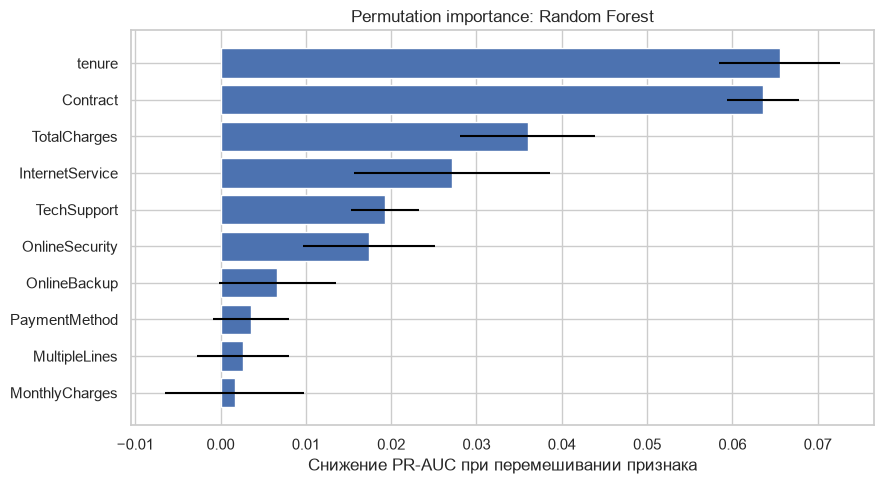

In [7]:
top_permutation = permutation_importance_df.head(10).sort_values("importance_mean")

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(
    top_permutation["feature"],
    top_permutation["importance_mean"],
    xerr=top_permutation["importance_std"],
    color="#4C72B0",
)

ax.set_title("Permutation importance: Random Forest")
ax.set_xlabel("Снижение PR-AUC при перемешивании признака")
ax.set_ylabel("")

plt.tight_layout()
plt.show()

In [8]:
preprocessor = best_model.named_steps["preprocessor"]
estimator = best_model.named_steps["model"]
feature_names = [name.split("__", 1)[1] for name in preprocessor.get_feature_names_out()]

default_importance = (
    pd.Series(estimator.feature_importances_, index=feature_names)
    .sort_values(ascending=False)
)

default_importance.head(10).round(4)

Contract_Month-to-month           0.1436
tenure                            0.1392
TotalCharges                      0.1141
MonthlyCharges                    0.0704
TechSupport_No                    0.0661
OnlineSecurity_No                 0.0639
InternetService_Fiber optic       0.0558
PaymentMethod_Electronic check    0.0494
Contract_Two year                 0.0357
InternetService_DSL               0.0234
dtype: float64

In [9]:
default_importance.rename("importance").to_csv(
    REPORTS_DIR / "default_feature_importance.csv",
    encoding="utf-8",
)

print("Сохранено:", REPORTS_DIR / "default_feature_importance.csv")

Сохранено: C:\Users\rrr9g\OneDrive\Рабочий стол\Projects\project1\reports\default_feature_importance.csv


Permutation importance на тесте ставит на первые места `tenure`, `Contract`, `TotalCharges`, `InternetService`, `TechSupport` и `OnlineSecurity`. Встроенная важность Random Forest тоже выделяет договор, стаж и платежи, но даёт более высокий вес отдельным one-hot колонкам: `Contract_Month-to-month`, `TechSupport_No`, `OnlineSecurity_No`, `InternetService_Fiber optic`.

Различия ожидаемы. Permutation importance перемешивает весь исходный признак целиком, а встроенная важность оценивает отдельные категории после One-Hot Encoding. Кроме того, `MonthlyCharges` и `TotalCharges` коррелированы: перемешивание одного из них может частично компенсироваться другим, поэтому вклад `MonthlyCharges` выглядит низким.

Оба метода показывают согласованную картину, но не доказывают причинно-следственную связь.

## 3. Чувствительность к порогу

Порог 0,2781 был выбран по OOF-предсказаниям с требованием Recall ≥ 0,80. Посмотрю, как меняются Precision, Recall и F1 при других порогах. Это помогает обсуждать компромисс с бизнесом.

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

oof_probabilities = cross_val_predict(
    best_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1,
)[:, 1]

thresholds = [0.10, 0.15, 0.20, 0.25, 0.2781, 0.30, 0.40, 0.50]
threshold_rows = []

for threshold in thresholds:
    predictions = (oof_probabilities >= threshold).astype(int)
    threshold_rows.append(
        {
            "threshold": threshold,
            "precision": precision_score(y_train, predictions, zero_division=0),
            "recall": recall_score(y_train, predictions),
            "f1": f1_score(y_train, predictions),
            "flagged_share": predictions.mean(),
        }
    )

threshold_sensitivity = pd.DataFrame(threshold_rows).set_index("threshold")
threshold_sensitivity.round(4)

,precision,recall,f1,flagged_share
threshold,,,,
0.1000,0.3809,0.9518,0.5441,0.6631
0.1500,0.4329,0.9144,0.5876,0.5605
0.2000,0.4674,0.8689,0.6079,0.4933
0.2500,0.5086,0.8288,0.6304,0.4324
0.2781,0.5235,0.7987,0.6324,0.4049
0.3000,0.5403,0.7753,0.6368,0.3807
0.4000,0.6074,0.6448,0.6256,0.2817
0.5000,0.6708,0.5043,0.5758,0.1995


In [11]:
threshold_sensitivity.round(4).to_csv(
    REPORTS_DIR / "threshold_sensitivity.csv",
    encoding="utf-8",
)

print("Сохранено:", REPORTS_DIR / "threshold_sensitivity.csv")

Сохранено: C:\Users\rrr9g\OneDrive\Рабочий стол\Projects\project1\reports\threshold_sensitivity.csv


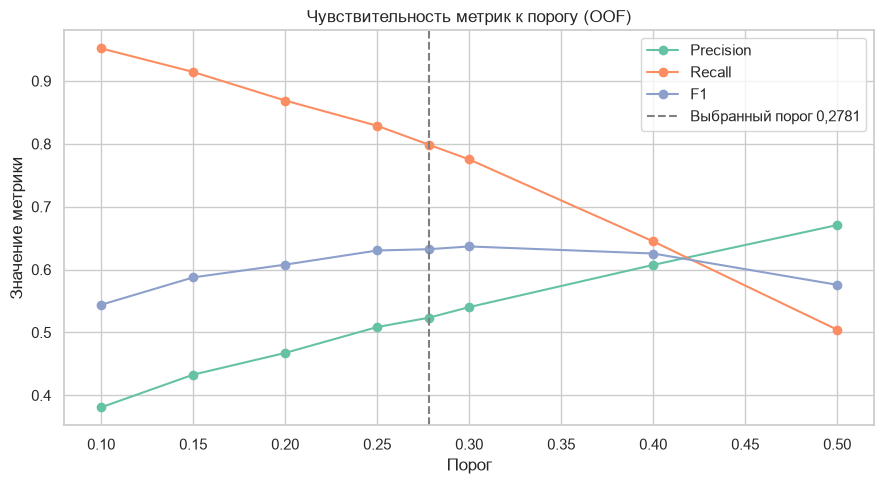

In [12]:
fig, ax = plt.subplots(figsize=(9, 5))

for column, label in [
    ("precision", "Precision"),
    ("recall", "Recall"),
    ("f1", "F1"),
]:
    ax.plot(
        threshold_sensitivity.index,
        threshold_sensitivity[column],
        marker="o",
        label=label,
    )

ax.axvline(0.2781, color="gray", linestyle="--", label="Выбранный порог 0,2781")
ax.set_xlabel("Порог")
ax.set_ylabel("Значение метрики")
ax.set_title("Чувствительность метрик к порогу (OOF)")
ax.legend()

plt.tight_layout()
plt.show()

При пороге 0,2781 на OOF: Precision — **0,5235**, Recall — **0,7987**, F1 — **0,6324**; модель отмечает **40,49%** клиентов. При пороге 0,3 F1 немного выше (0,6368), но Recall снижается до 0,7753. При пороге 0,5 Precision растёт до 0,6708, а Recall падает до 0,5043.

Диапазон 0,25–0,30 выглядит разумным компромиссом, если цель — не пропустить большинство уходящих. Окончательный порог должен зависеть от стоимости контакта и эффективности удержания.

## 4. Выводы

**Устойчивость.** Repeated 5×3 CV даёт PR-AUC **0,6649 ± 0,0212** и ROC-AUC **0,8486 ± 0,0115**. Метрики близки к одиночной 5-fold, но разброс PR-AUC около 0,02 — различия между Random Forest и Logistic Regression находятся в пределах этой вариации. Модель можно считать умеренно устойчивой; для более надёжного сравнения нужны дополнительные seed и, возможно, временная валидация.

**Важность признаков.** Оба метода согласованно выделяют стаж, тип договора и суммарные платежи. Permutation importance дополнительно подчёркивает интернет-услуги и техподдержку. Расхождения по `MonthlyCharges` объясняются корреляцией с `TotalCharges` и разным уровнем детализации: исходный признак против one-hot категорий. Это интерпретация модели, а не причинно-следственные выводы.

**Порог.** Порог 0,2781 даёт Recall около 0,80 при Precision около 0,52. Если бизнесу важнее не пропускать уходящих, этот диапазон подходит; если важнее снизить число лишних контактов, стоит поднять порог до 0,4–0,5. Решение зависит от стоимости контакта и ожидаемого эффекта удержания.

**Ограничения.** Permutation importance считается на тестовой выборке и может быть нестабильной при коррелированных признаках. Повторная CV использует те же данные и не заменяет временную проверку. Все выводы относятся к демонстрационному срезу.